# 20nodes_EB_obsconf6_latconf0_Gaussian_Linear: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf6_latconf0_Gaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.476564,0.068130,15
1,DAGMA_Linear,0.183086,0.107450,15
2,DAGMA_Nonlinear,0.109549,0.047424,15
3,DAS,0.117891,0.058746,15
4,DirectLiNGAM,0.315920,0.079424,15
5,FCI,0.089455,0.063986,15
6,GES,0.422505,0.201050,14
7,GOLEM,0.124155,0.054924,15
8,GRaSP,0.781358,0.077529,15
9,GraNDAG,0.062104,0.032118,15


,model,mean,std,size
0,AVICI,59.000000,12.878554,15
1,DAGMA_Linear,61.066667,10.031854,15
2,DAGMA_Nonlinear,75.457778,10.233833,15
3,DAS,102.266667,15.831554,15
4,DirectLiNGAM,112.200000,21.474902,15
5,FCI,60.666667,8.607859,15
6,GES,83.000000,36.624918,14
7,GOLEM,86.466667,12.211626,15
8,GRaSP,24.200000,11.000664,15
9,GraNDAG,56.466667,6.875076,15


,model,mean,std,size
0,AVICI,0.479803,0.064308,15
1,DAGMA_Linear,0.239632,0.123192,15
2,DAGMA_Nonlinear,0.119786,0.044337,15
3,DAS,0.095370,0.047870,15
4,DirectLiNGAM,0.225100,0.062203,15
5,FCI,0.522619,0.287280,15
6,GES,0.351680,0.220699,14
7,GOLEM,0.116254,0.054462,15
8,GRaSP,0.773828,0.089674,15
9,GraNDAG,0.554286,0.323379,15


,model,mean,std,size
0,AVICI,0.494908,0.130440,15
1,DAGMA_Linear,0.150277,0.097776,15
2,DAGMA_Nonlinear,0.103405,0.052411,15
3,DAS,0.155515,0.078133,15
4,DirectLiNGAM,0.535167,0.111867,15
5,FCI,0.049809,0.036909,15
6,GES,0.561018,0.162089,14
7,GOLEM,0.134982,0.058106,15
8,GRaSP,0.797347,0.071760,15
9,GraNDAG,0.034062,0.018590,15


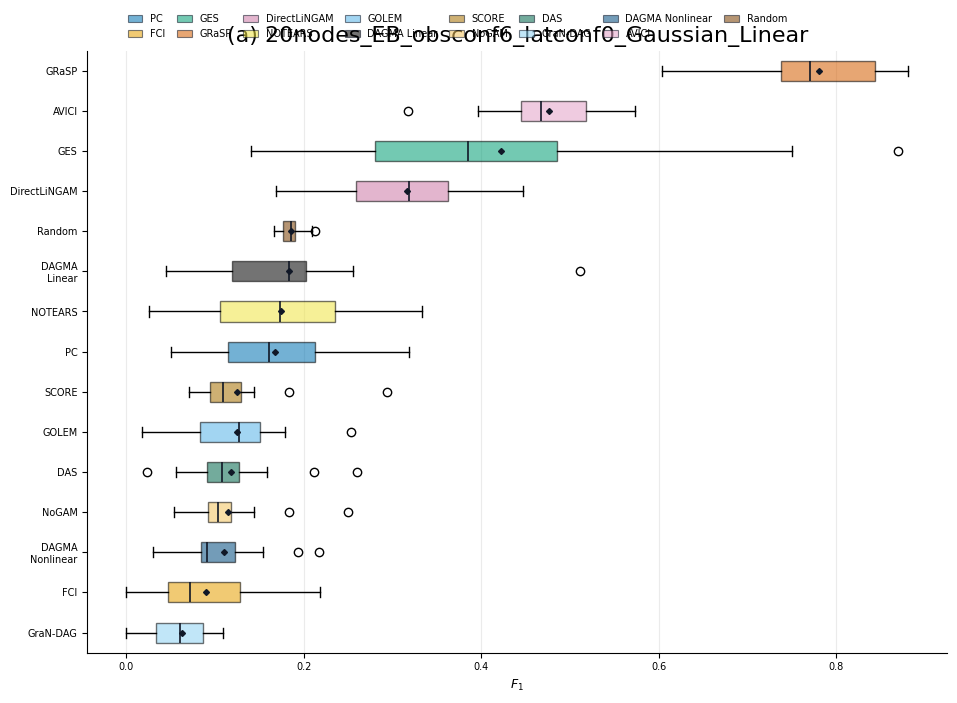

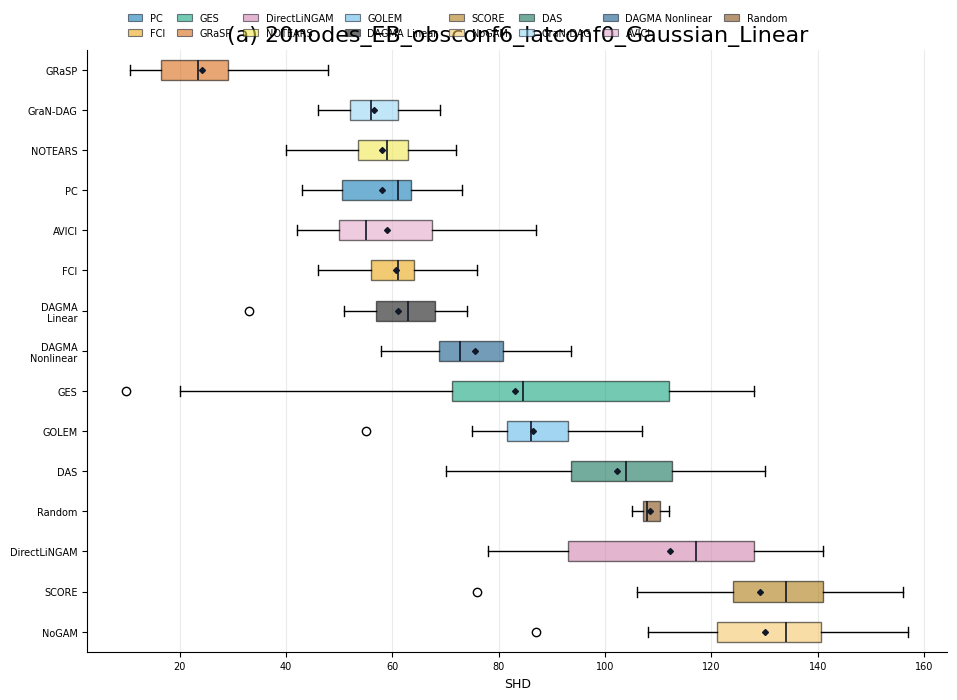

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.212940
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.567879
9,13,GraNDAG,0.000000


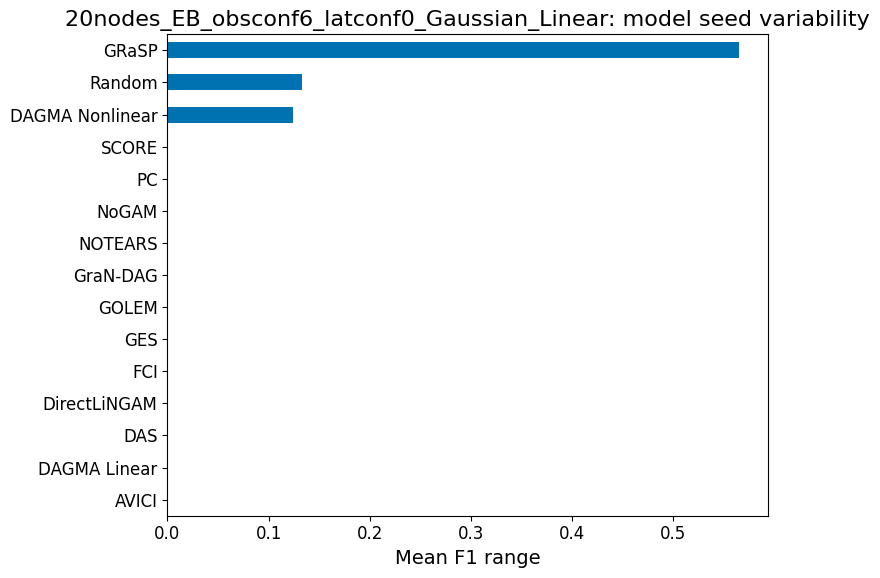

,model_seed,model,f1_range
0,0,AVICI,0.256156
1,0,DAGMA_Linear,0.467183
2,0,DAGMA_Nonlinear,0.235897
3,0,DAS,0.237305
4,0,DirectLiNGAM,0.278045
5,0,FCI,0.218182
6,0,GES,0.729025
7,0,GOLEM,0.235240
8,0,GRaSP,0.415830
9,0,GraNDAG,0.109091


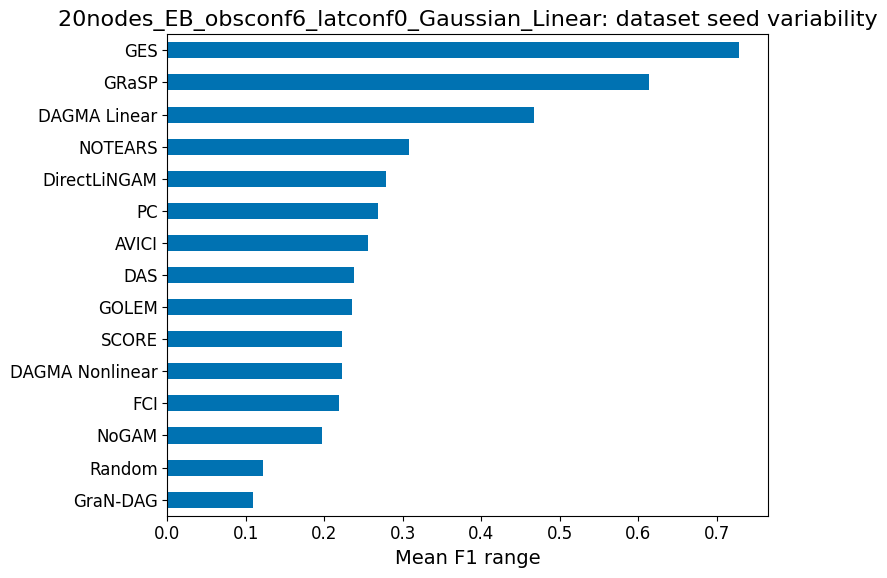

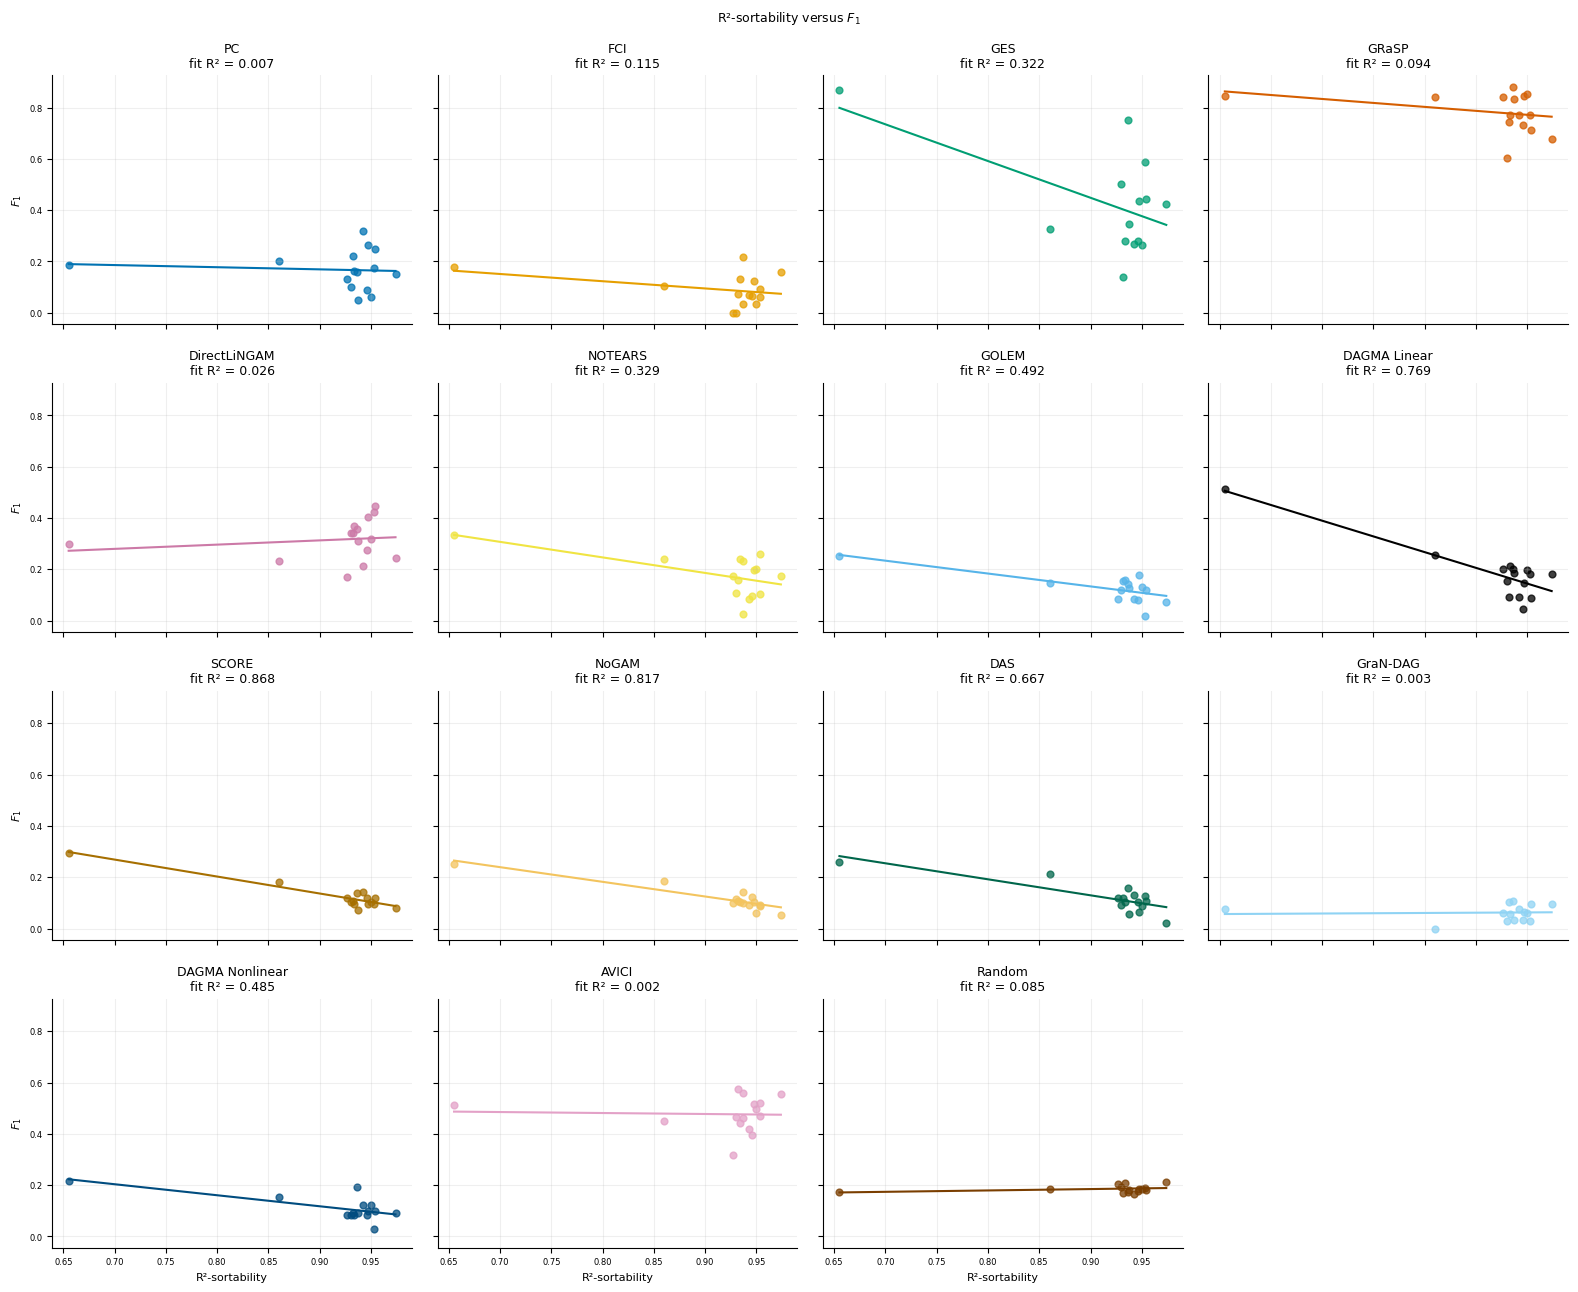

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,AVICI,0.417582,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
1,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Linear,0.090909,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
2,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.120855,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
3,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAS,0.129032,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
4,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DirectLiNGAM,0.214286,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
5,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,FCI,0.070175,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
6,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GES,0.268156,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
7,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GOLEM,0.084034,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
8,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GRaSP,0.770618,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
9,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GraNDAG,0.075472,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.984556,0.949807,259,255,0,246,0,20,2000
1,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
2,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.965517,0.655172,145,140,0,95,0,20,2000
3,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.989637,0.860104,193,191,0,166,0,20,2000
4,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.992453,0.947170,265,263,0,251,0,20,2000
5,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.975610,0.936585,205,200,0,192,0,20,2000
6,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.996875,0.953125,320,319,0,305,0,20,2000
7,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.986034,0.930168,358,353,0,333,0,20,2000
8,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.987864,0.953883,412,407,0,393,0,20,2000
9,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.990499,0.973872,421,417,0,410,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.042992,0.001848,-0.038109,0.511569,8.790844e-01,0.282143,0.308284
1,DAGMA_Linear,15,-0.876984,0.769101,-1.226037,1.309248,1.768191e-05,-0.561216,0.029499
2,DAGMA_Nonlinear,15,-0.696449,0.485042,-0.429725,0.504267,3.919676e-03,-0.260714,0.347979
3,DAS,15,-0.816790,0.667146,-0.624300,0.691334,2.021327e-04,-0.550000,0.033655
4,DirectLiNGAM,15,0.160156,0.025650,0.165501,0.163901,5.685624e-01,0.375000,0.168433
5,FCI,15,-0.338570,0.114630,-0.281864,0.348358,2.170614e-01,0.005367,0.984855
6,GES,14,-0.567734,0.322322,-1.431696,1.736738,3.419485e-02,-0.063736,0.828626
7,GOLEM,15,-0.701488,0.492086,-0.501290,0.584608,3.563744e-03,-0.525000,0.044484
8,GRaSP,15,-0.306261,0.093796,-0.308933,1.065124,2.669187e-01,-0.300000,0.277317
9,GraNDAG,15,0.050972,0.002598,0.021300,0.042539,8.568365e-01,0.210714,0.450958


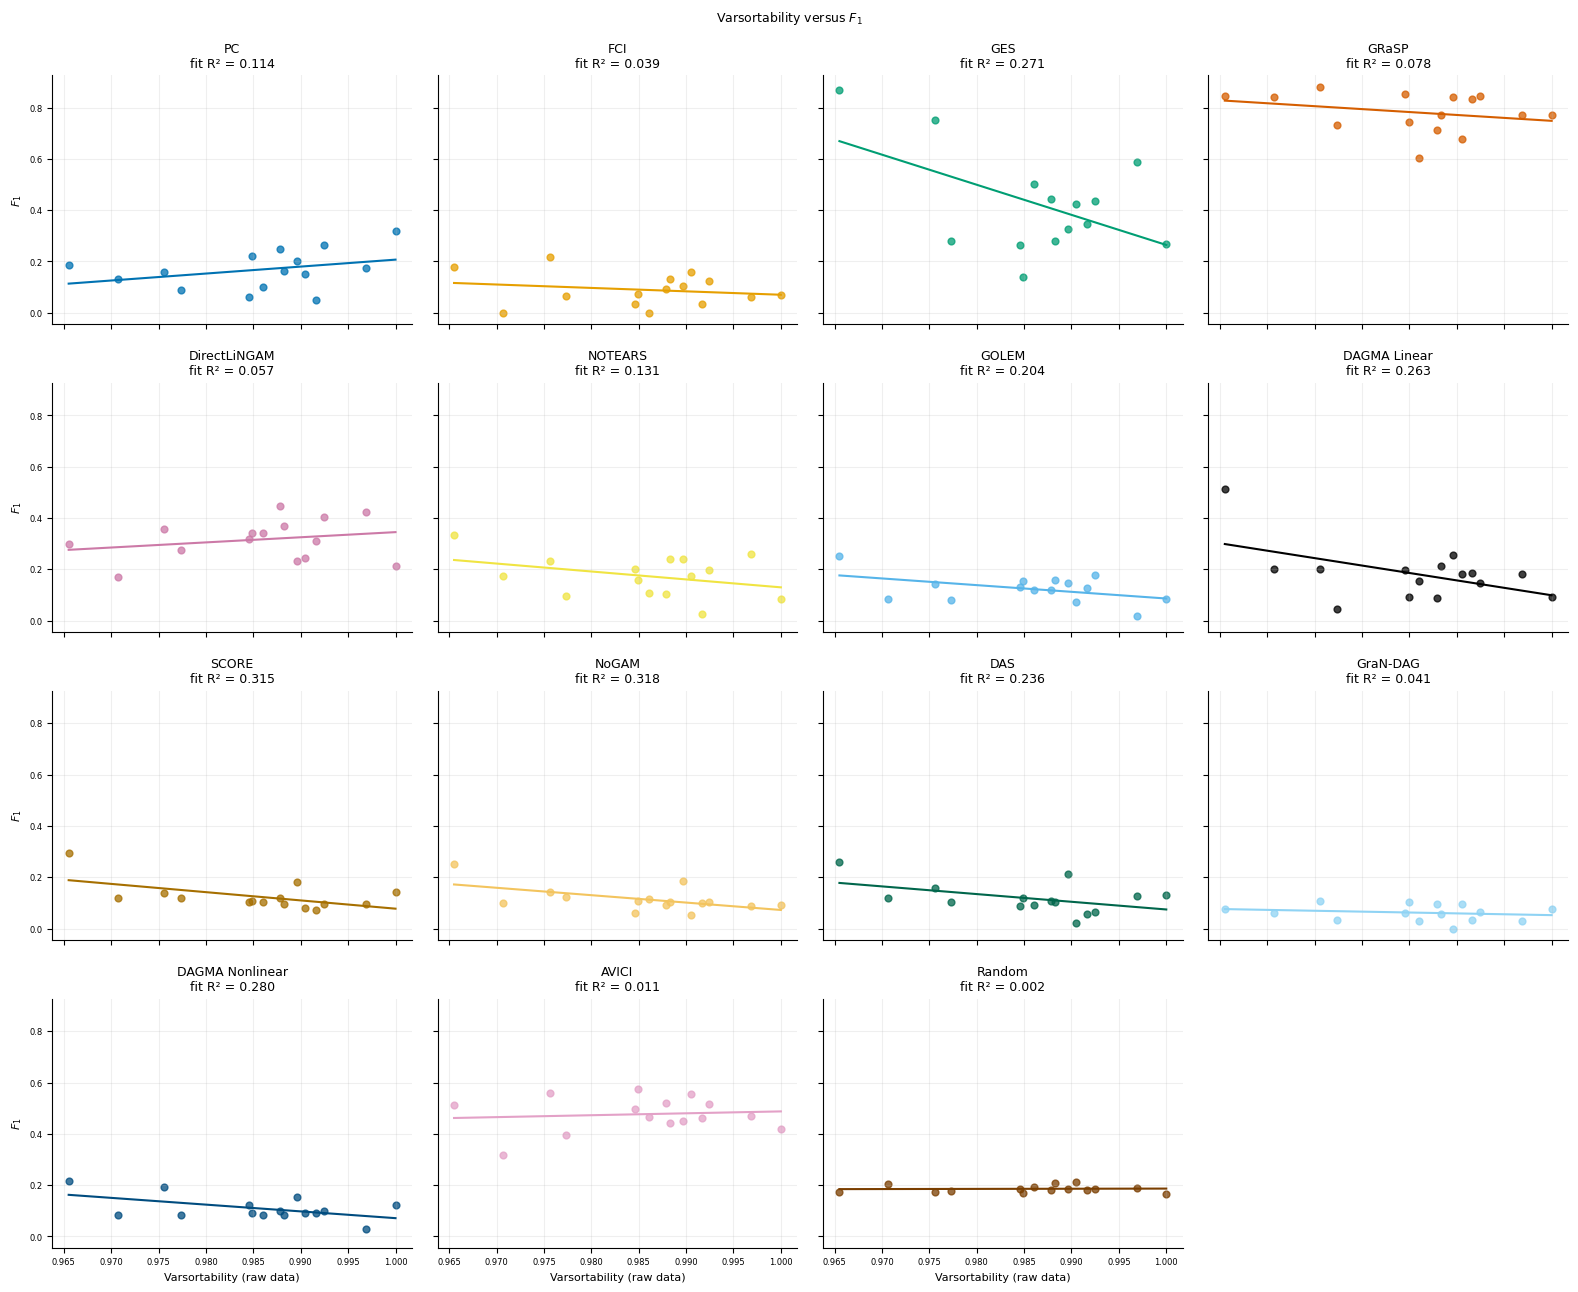

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,AVICI,0.417582,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
1,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Linear,0.090909,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
2,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.120855,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
3,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAS,0.129032,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
4,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DirectLiNGAM,0.214286,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
5,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,FCI,0.070175,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
6,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GES,0.268156,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
7,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GOLEM,0.084034,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
8,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GRaSP,0.770618,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
9,13,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GraNDAG,0.075472,15,20,EB,6,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.984556,0.949807,259,255,0,246,0,20,2000
1,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,1.000000,0.942408,191,191,0,180,0,20,2000
2,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.965517,0.655172,145,140,0,95,0,20,2000
3,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.989637,0.860104,193,191,0,166,0,20,2000
4,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.992453,0.947170,265,263,0,251,0,20,2000
5,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.975610,0.936585,205,200,0,192,0,20,2000
6,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.996875,0.953125,320,319,0,305,0,20,2000
7,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.986034,0.930168,358,353,0,333,0,20,2000
8,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.987864,0.953883,412,407,0,393,0,20,2000
9,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf6_latconf...,0.990499,0.973872,421,417,0,410,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.103973,0.010810,0.744891,-0.257495,0.712312,-0.060714,0.829812
1,DAGMA_Linear,15,-0.512600,0.262759,-5.791867,5.890730,0.050723,-0.323503,0.239518
2,DAGMA_Nonlinear,15,-0.528880,0.279714,-2.637463,2.708659,0.042654,-0.200000,0.474814
3,DAS,15,-0.485721,0.235925,-3.000531,3.074789,0.066422,-0.278571,0.314709
4,DirectLiNGAM,15,0.239569,0.057393,2.000866,-1.655850,0.389801,0.160714,0.567197
5,FCI,15,-0.197851,0.039145,-1.331244,1.401340,0.479670,-0.053667,0.849343
6,GES,14,-0.520121,0.270526,-11.737125,12.001346,0.056577,-0.129670,0.658619
7,GOLEM,15,-0.451866,0.204183,-2.609793,2.695997,0.090849,-0.232143,0.405099
8,GRaSP,15,-0.280164,0.078492,-2.284092,3.032235,0.311835,-0.285714,0.301936
9,GraNDAG,15,-0.202221,0.040893,-0.682981,0.735153,0.469819,-0.239286,0.390379


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf6_latconf0_Gaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.282143,0.308284,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.561216,0.029499,estimated,0.412992
2,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.260714,0.347979,estimated,1.000000
3,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DAS,r2_sortability,15,-0.550000,0.033655,estimated,0.437520
4,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.375000,0.168433,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,FCI,r2_sortability,15,0.005367,0.984855,estimated,1.000000
6,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GES,r2_sortability,14,-0.063736,0.828626,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GOLEM,r2_sortability,15,-0.525000,0.044484,estimated,0.533807
8,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GRaSP,r2_sortability,15,-0.300000,0.277317,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,GraNDAG,r2_sortability,15,0.210714,0.450958,estimated,1.000000
